# Land Cleared by Humanitarian Demining in Colombia, Before and After the 2016 Peace Agreement

**Author:** Travis Carlson
**Dataset:** *Situación de Desminado Humanitario en Colombia*, published by the Departamento Administrativo de la Presidencia de la República (DAPRE) on Colombia's national open data portal, datos.gov.co (CC BY-SA 4.0)

This notebook analyses Colombia's official record of humanitarian demining results from 2004 to 2023: 5,721 records of land cleared, explosive items found, surveys and hazardous areas, by municipality, month and operator. It checks and describes the data, compares three visual models and runs one hypothesis test on a question set in advance.

**Question.** Did humanitarian demining in Colombia clear more land each month after the 2016 peace agreement than before it?

**Analysis plan, fixed before the test was run.** Initial data analysis examines a dataset's properties for a research question set in advance and refrains from analyses related to that question, because decisions made after looking at the data can bias the results (Lusa et al., 2024). The plan:
- **Unit:** the national total of land cleared in each month: 84 months from January 2010 to December 2016 against 84 months from January 2017 to December 2023. A month with no record counts as zero.
- **Test:** Mann–Whitney U, two-sided, with α = 0.05. Reported: U, the p-value, the median of each period and the rank-biserial correlation as the effect size.
- **Check:** the same test on yearly totals, 7 years against 7, which does not treat months as independent.
- **Left out of the test:** 2004 to 2009, while operations were starting (1 to 50 records a year). These years still appear in the descriptive statistics and the first chart.
- The yearly totals had been seen when the question was chosen, so the test confirms a visible pattern rather than a blind prediction.

Sections 2 and 3 check the data and screen the properties the test depends on; sections 4 and 5 compare land cleared between the periods.

*Reference:* Lusa, L., Proust-Lima, C., Schmidt, C. O., Lee, K. J., le Cessie, S., Baillie, M., Lawrence, F., & Huebner, M. (2024). Initial data analysis for longitudinal studies to build a solid foundation for reproducible analysis. *PLOS ONE, 19*(5), e0295726. https://doi.org/10.1371/journal.pone.0295726

## 1. Setup

Libraries, file locations, the provenance of the raw file, the fixed settings of the analysis plan, and one chart style used throughout. The analysis uses Python, NumPy, Pandas, Matplotlib, Seaborn and SciPy.

In [1]:
import hashlib
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
import seaborn as sns
import scipy
from scipy import stats

pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 120)

# Files (the raw file sits in the same folder as this notebook)
DATA_FILE = Path("desminado_humanitario.csv")
FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Provenance of the raw file
SOURCE_PAGE = ("https://www.datos.gov.co/Inclusi-n-Social-y-Reconciliaci-n/"
               "Situaci-n-de-Desminado-Humanitario-en-Colombia/jbqm-s5tn")
DOWNLOAD_URL = "https://www.datos.gov.co/api/views/jbqm-s5tn/rows.csv?accessType=DOWNLOAD"
DOWNLOADED_ON = "2026-10-18"
EXPECTED_SHA256 = "eda568a71903f05d7468c582b3795dbd5a537a71c5413f84f72f0acbcffb6617"

# Analysis plan, fixed before the test was run (see the introduction)
START_UP, BEFORE, AFTER = "2004–2009", "2010–2016", "2017–2023"
ALPHA = 0.05
MILITARY_OPERATORS = {"BRDEH", "BDIAN"}  # the Army's and the Navy's humanitarian demining units

# Chart style: light surface, quiet grid, and one fixed colour per period in every chart
SURFACE, INK, INK_2, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
PERIOD_COLOURS = {START_UP: MUTED, BEFORE: "#2a78d6", AFTER: "#eb6834"}
THOUSANDS = FuncFormatter(lambda value, _: f"{value:,.0f}")

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": BASELINE, "axes.labelcolor": INK_2, "axes.titlecolor": INK,
    "axes.titlesize": 12, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 1, "grid.linestyle": "-",
    "axes.axisbelow": True, "xtick.color": MUTED, "ytick.color": MUTED,
    "text.color": INK, "font.size": 10, "lines.linewidth": 2, "legend.frameon": False,
})

for name, module in [("pandas", pd), ("numpy", np), ("matplotlib", matplotlib),
                     ("seaborn", sns), ("scipy", scipy)]:
    print(f"{name:<10} {module.__version__}")

pandas     3.0.6
numpy      2.5.4
matplotlib 3.11.2
seaborn    0.13.2
scipy      1.18.1


## 2. Data handling

### 2.1 Load the raw file

The raw file is a snapshot of the portal's CSV export, kept unchanged next to this notebook. Its SHA-256 checksum is compared with the one recorded when it was downloaded, so anyone rerunning the notebook can confirm they are using the same data. The portal's metadata gives the publisher, the licence, a description of each column and the date the rows were last updated (19 January 2024).

In [2]:
def file_sha256(path):
    """Return the SHA-256 checksum of a file, reading it in 1 MB chunks.

    Used to confirm that the raw file is the snapshot recorded when it was downloaded.
    A different checksum means a newer download or a changed file.
    """
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


checksum = file_sha256(DATA_FILE)
print(f"Source page:   {SOURCE_PAGE}")
print(f"Downloaded on: {DOWNLOADED_ON}")
print(f"SHA-256:       {checksum}")
if checksum == EXPECTED_SHA256:
    print("Checksum matches the recorded snapshot.")
else:
    print("WARNING: checksum differs from the recorded snapshot; results may not match the report.")

df_raw = pd.read_csv(DATA_FILE, encoding="utf-8")
print(f"\nLoaded {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head()

Source page:   https://www.datos.gov.co/Inclusi-n-Social-y-Reconciliaci-n/Situaci-n-de-Desminado-Humanitario-en-Colombia/jbqm-s5tn
Downloaded on: 2026-10-18
SHA-256:       eda568a71903f05d7468c582b3795dbd5a537a71c5413f84f72f0acbcffb6617
Checksum matches the recorded snapshot.

Loaded 5,721 rows x 18 columns


,departamento,codigodanedepartamento,municipio,codigodanemunicipio,ano,mes,tipodesminado,areadespejada,map,muse,aei,totalartefactosdestruidos,organizacion,estudiosnotecnicos,estudiostecnicos,operacionesdespeje,areaspeligrosas,areaspeligrosasconfirmadas
0,CAUCA,19,CALOTO,19142,2018,4,Comunidades,0.0,0,0,0,0,HI,3,0,0,0,0
1,META,50,LA MACARENA,50350,2019,9,Comunidades,1563.0,0,148,0,148,BRDEH,0,0,1,0,0
2,SANTANDER,68,SIMACOTA,68745,2020,7,Comunidades,6499.0,0,0,0,0,BRDEH,0,0,1,0,0
3,TOLIMA,73,RONCESVALLES,73622,2022,10,Comunidades,0.0,0,0,0,0,BRDEH,0,0,0,1,0
4,CAUCA,19,PÁEZ,19517,2023,2,Comunidades,0.0,0,0,0,0,HI,4,0,0,0,0


In [3]:
df_raw.info()
fractional = (df_raw["areadespejada"] % 1 != 0).sum()
print(f"\nRecords whose land cleared has a fractional part: {fractional}")

<class 'pandas.DataFrame'>
RangeIndex: 5721 entries, 0 to 5720
Data columns (total 18 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   departamento                5721 non-null   str    
 1   codigodanedepartamento      5721 non-null   int64  
 2   municipio                   5721 non-null   str    
 3   codigodanemunicipio         5721 non-null   int64  
 4   ano                         5721 non-null   int64  
 5   mes                         5721 non-null   int64  
 6   tipodesminado               5721 non-null   str    
 7   areadespejada               5721 non-null   float64
 8   map                         5721 non-null   int64  
 9   muse                        5721 non-null   int64  
 10  aei                         5721 non-null   int64  
 11  totalartefactosdestruidos   5721 non-null   int64  
 12  organizacion                5721 non-null   str    
 13  estudiosnotecnicos          5721 non-null   

All 18 columns loaded, with no empty cells. Text columns were read as strings and the counts as integers. Two types need attention: the official DANE codes for departments and municipalities were read as numbers, which drops their leading zero, and land cleared was read as a decimal number because 67 records report fractions of a square metre.

### 2.2 Data dictionary and preparation

Column descriptions from the portal's metadata, with the English names used below.

| Published column | English name | Meaning (portal description) |
|---|---|---|
| `departamento`, `codigodanedepartamento` | `department`, `department_code` | Department where demining took place, and its DANE code |
| `municipio`, `codigodanemunicipio` | `municipality`, `municipality_code` | Municipality, and its DANE code |
| `ano`, `mes` | `year`, `month` | Year and month of the work |
| `tipodesminado` | `demining_type` | Demining on military bases or in communities |
| `areadespejada` | `area_cleared_m2` | Land cleared, in square metres |
| `map`, `muse`, `aei` | `items_mines`, `items_uxo`, `items_ieds` | Items found: antipersonnel mines, unexploded ordnance and improvised explosive devices |
| `totalartefactosdestruidos` | `items_total` | Total items. The column name says destroyed; the portal's description says found |
| `organizacion` | `operator` | Organisation that reported the information |
| `estudiosnotecnicos`, `estudiostecnicos` | `non_technical_surveys`, `technical_surveys` | Non-technical and technical surveys carried out |
| `operacionesdespeje` | `clearance_operations` | Clearance operations carried out |
| `areaspeligrosas`, `areaspeligrosasconfirmadas` | `hazardous_areas`, `confirmed_hazardous_areas` | Hazardous areas recorded, and confirmed |

The preparation function renames the columns, stores the codes as zero-padded text (the reliable key, since some municipality names repeat across departments), translates the demining type, and adds two grouping columns: the operator type (military or civilian) and the period of the analysis plan. It returns a new table, so the raw data stays unchanged.

In [4]:
COLUMN_MAP = {
    "departamento": "department", "codigodanedepartamento": "department_code",
    "municipio": "municipality", "codigodanemunicipio": "municipality_code",
    "ano": "year", "mes": "month", "tipodesminado": "demining_type",
    "areadespejada": "area_cleared_m2",
    "map": "items_mines", "muse": "items_uxo", "aei": "items_ieds",
    "totalartefactosdestruidos": "items_total", "organizacion": "operator",
    "estudiosnotecnicos": "non_technical_surveys", "estudiostecnicos": "technical_surveys",
    "operacionesdespeje": "clearance_operations",
    "areaspeligrosas": "hazardous_areas", "areaspeligrosasconfirmadas": "confirmed_hazardous_areas",
}
DEMINING_TYPES = {"Comunidades": "Communities", "Bases Militares": "Military bases"}
ITEMS = ["items_mines", "items_uxo", "items_ieds"]
RESULTS = ["area_cleared_m2", *ITEMS, "items_total",
           "non_technical_surveys", "technical_surveys", "clearance_operations"]
HAZARDS = ["hazardous_areas", "confirmed_hazardous_areas"]
MEASURES = RESULTS + HAZARDS


def period_of(year):
    """Return the analysis-plan period for a year: start-up, before or after 2016."""
    if year <= 2009:
        return START_UP
    return BEFORE if year <= 2016 else AFTER


def prepare(raw):
    """Return a renamed, typed copy of the raw table with operator type and period added."""
    df = raw.rename(columns=COLUMN_MAP)
    df["department_code"] = df["department_code"].astype(str).str.zfill(2)
    df["municipality_code"] = df["municipality_code"].astype(str).str.zfill(5)
    df["demining_type"] = df["demining_type"].map(DEMINING_TYPES)
    df["operator_type"] = np.where(df["operator"].isin(MILITARY_OPERATORS), "Military", "Civilian")
    df["period"] = df["year"].map(period_of)
    return df


df = prepare(df_raw)
assert df["demining_type"].notna().all(), "unexpected demining type"
df.head()

,department,department_code,municipality,municipality_code,year,month,demining_type,area_cleared_m2,items_mines,items_uxo,items_ieds,items_total,operator,non_technical_surveys,technical_surveys,clearance_operations,hazardous_areas,confirmed_hazardous_areas,operator_type,period
0,CAUCA,19,CALOTO,19142,2018,4,Communities,0.0,0,0,0,0,HI,3,0,0,0,0,Civilian,2017–2023
1,META,50,LA MACARENA,50350,2019,9,Communities,1563.0,0,148,0,148,BRDEH,0,0,1,0,0,Military,2017–2023
2,SANTANDER,68,SIMACOTA,68745,2020,7,Communities,6499.0,0,0,0,0,BRDEH,0,0,1,0,0,Military,2017–2023
3,TOLIMA,73,RONCESVALLES,73622,2022,10,Communities,0.0,0,0,0,0,BRDEH,0,0,0,1,0,Military,2017–2023
4,CAUCA,19,PÁEZ,19517,2023,2,Communities,0.0,0,0,0,0,HI,4,0,0,0,0,Civilian,2017–2023


### 2.3 Data checks

Before any totals are added up, four checks: empty cells and repeated rows; whether the item total equals its three parts; rows that share a municipality, month, demining type and operator; and which months have records.

In [5]:
print(f"Empty cells: {df.isna().sum().sum()}")
print(f"Rows that repeat another row exactly: {df.duplicated().sum()}")
items_match = df[ITEMS].sum(axis=1).eq(df["items_total"])
print(f"Rows where items_total equals mines + UXO + IEDs: {items_match.sum():,} of {len(df):,}")
print(f"Municipality codes: {df['municipality_code'].nunique()}; "
      f"municipality names: {df['municipality'].nunique()} (some names repeat across departments)")

Empty cells: 0
Rows that repeat another row exactly: 0
Rows where items_total equals mines + UXO + IEDs: 5,721 of 5,721
Municipality codes: 435; municipality names: 418 (some names repeat across departments)


In [6]:
KEY = ["municipality_code", "year", "month", "demining_type", "operator"]


def repeated_key_check(df, key):
    """Check rows that share a key: do they repeat a measure, or split the measures between them?

    Returns the number of key combinations that appear more than once, and for each measure the
    number of those combinations in which more than one row reports a non-zero value. A zero for
    every measure means the shared rows never repeat a measure, so summing rows double-counts nothing.
    """
    shared = df[df.duplicated(key, keep=False)]
    nonzero_rows = shared[MEASURES].ne(0).groupby([shared[k] for k in key]).sum()
    return len(nonzero_rows), (nonzero_rows > 1).sum()


combinations, repeated_measures = repeated_key_check(df, KEY)
print(f"Combinations of municipality, month, demining type and operator that appear twice: {combinations:,}")
print("Combinations in which a measure is non-zero in more than one row:")
print(repeated_measures.to_string())

reports_results = df[RESULTS].ne(0).any(axis=1)
reports_hazards = df[HAZARDS].ne(0).any(axis=1)
print("\nWhat each row reports:")
pd.crosstab(reports_results.map({True: "Reports results", False: "No results"}),
            reports_hazards.map({True: "Reports hazardous areas", False: "No hazardous areas"}),
            rownames=["Results"], colnames=["Hazardous areas"])

Combinations of municipality, month, demining type and operator that appear twice: 1,183
Combinations in which a measure is non-zero in more than one row:
area_cleared_m2              0
items_mines                  0
items_uxo                    0
items_ieds                   0
items_total                  0
non_technical_surveys        0
technical_surveys            0
clearance_operations         0
hazardous_areas              0
confirmed_hazardous_areas    0

What each row reports:


Hazardous areas,No hazardous areas,Reports hazardous areas
Results,,
No results,16,1705
Reports results,4000,0


In [7]:
records_per_month = df.groupby(["year", "month"]).size()
all_months = pd.MultiIndex.from_product([range(2004, 2024), range(1, 13)], names=["year", "month"])
missing = all_months.difference(records_per_month.index)
print(f"Months from 2004 to 2023 with no record: {len(missing)}")
print(pd.Series(missing.get_level_values("year")).value_counts().sort_index().to_string())

late = records_per_month.unstack("month").loc[[2022, 2023], 9:12].fillna(0).astype(int)
print("\nRecords in September to December, 2022 and 2023:")
late

Months from 2004 to 2023 with no record: 37
year
2004    11
2005    10
2006     5
2007     3
2008     4
2009     1
2011     1
2012     1
2023     1

Records in September to December, 2022 and 2023:


month,9,10,11,12
year,,,,
2022,56,54,47,25
2023,23,6,1,0


**What the checks show.**
- No cell is empty, no row repeats another exactly, and the item total always equals the three item types.
- 1,183 combinations of municipality, month, demining type and operator appear twice, but the two rows never report the same measure. No row reports both results (land cleared, items found, surveys, clearance operations) and hazardous areas, and each pair joins a row of hazardous areas with a row of results (in three pairs, with an empty row). Inference: the published file joins two kinds of record. Summing the rows therefore gives correct totals, and none of the paired rows should be deleted as duplicates.
- Of the 37 months with no record, 34 fall in the start-up years 2004 to 2009. Within the test window there are three: January 2011, January 2012 and December 2023.
- Records thin out at the end of 2023: 23 in September, 6 in October, 1 in November and none in December, against 56, 54, 47 and 25 in the same months of 2022. Inference: the rows were last updated on 19 January 2024, so the last months of 2023 were probably not yet fully reported. The plan counts December 2023 as zero; if that month is really missing, counting it as zero lowers the after-2016 group, so it works against finding a rise.
- The portal describes the data as starting in 2005; the file also holds one record from 2004, a military-base record with nothing cleared.

## 3. Descriptive statistics

Summary statistics, counts of the categorical columns and the distributions of the numeric ones, followed by the properties of the monthly totals that the test depends on. Following the plan, this section screens the data's properties and does not yet compare how much land each period cleared; that comparison starts in section 4.

### 3.1 Summary statistics

In [8]:
df[MEASURES].describe().T.round(1)

,count,mean,std,min,25%,50%,75%,max
area_cleared_m2,5721.0,2380.4,6983.4,0.0,0.0,0.0,1068.0,145335.0
items_mines,5721.0,1.2,13.5,0.0,0.0,0.0,0.0,476.0
items_uxo,5721.0,0.3,3.5,0.0,0.0,0.0,0.0,155.0
items_ieds,5721.0,0.1,1.1,0.0,0.0,0.0,0.0,63.0
items_total,5721.0,1.6,14.2,0.0,0.0,0.0,0.0,476.0
non_technical_surveys,5721.0,1.8,3.6,0.0,0.0,1.0,2.0,85.0
technical_surveys,5721.0,0.1,0.6,0.0,0.0,0.0,0.0,11.0
clearance_operations,5721.0,0.3,0.7,0.0,0.0,0.0,0.0,10.0
hazardous_areas,5721.0,0.3,0.8,0.0,0.0,0.0,0.0,17.0
confirmed_hazardous_areas,5721.0,0.3,0.7,0.0,0.0,0.0,0.0,8.0


Each record covers one municipality, month, demining type and operator, so most measures are zero in most records: the median is zero for every measure except non-technical surveys. Means far above the medians, and maximums far above the 75th percentiles, show that a few records hold most of the land cleared and the items found. The record with the most land cleared reports 145,335 m², while the mean is 2,380 m².

### 3.2 Categorical counts

In [9]:
def count_and_share(df, column):
    """Return the number and percentage of records in each category of a column, largest first."""
    counts = df[column].value_counts().rename_axis(column).reset_index(name="records")
    counts["share %"] = (counts["records"] / len(df) * 100).round(1)
    return counts


for column in ["demining_type", "operator_type", "period"]:
    display(count_and_share(df, column))

,demining_type,records,share %
0,Communities,5657,98.9
1,Military bases,64,1.1


,operator_type,records,share %
0,Military,3649,63.8
1,Civilian,2072,36.2


,period,records,share %
0,2017–2023,4546,79.5
1,2010–2016,1071,18.7
2,2004–2009,104,1.8


In [10]:
operators = df.groupby("operator").agg(
    type=("operator_type", "first"), records=("operator", "size"),
    first_year=("year", "min"), last_year=("year", "max"),
    area_cleared_m2=("area_cleared_m2", "sum"))
operators["share of land cleared %"] = (operators["area_cleared_m2"] / df["area_cleared_m2"].sum() * 100).round(1)
operators["area_cleared_m2"] = operators["area_cleared_m2"].round(0).astype(int)
operators.sort_values("records", ascending=False)

,type,records,first_year,last_year,area_cleared_m2,share of land cleared %
operator,,,,,,
BRDEH,Military,3394,2004,2023,11022345,80.9
HALO,Civilian,1001,2013,2023,1631541,12.0
CCCM,Civilian,560,2017,2023,325183,2.4
HI,Civilian,279,2016,2023,224391,1.6
BDIAN,Military,255,2015,2023,266156,2.0
DRC,Civilian,99,2018,2023,63214,0.5
APN,Civilian,76,2015,2020,69335,0.5
HUMANICEMOS,Civilian,40,2020,2023,13295,0.1
PERIGEO,Civilian,9,2018,2019,2919,0.0


In [11]:
for period in [BEFORE, AFTER]:
    names = sorted(df.loc[df["period"] == period, "operator"].unique())
    print(f"Operators with records in {period}: {len(names)} ({', '.join(names)})")

military_bases = df[df["demining_type"] == "Military bases"]
print(f"\nMilitary-base records: {len(military_bases)}, from {military_bases['year'].min()} "
      f"to {military_bases['year'].max()}, operator(s): {', '.join(military_bases['operator'].unique())}; "
      f"{military_bases['area_cleared_m2'].sum() / df['area_cleared_m2'].sum():.1%} of all land cleared")

Operators with records in 2010–2016: 5 (APN, BDIAN, BRDEH, HALO, HI)
Operators with records in 2017–2023: 10 (APN, ATEXX, BDIAN, BRDEH, CCCM, DRC, HALO, HI, HUMANICEMOS, PERIGEO)

Military-base records: 64, from 2004 to 2010, operator(s): BRDEH; 1.2% of all land cleared


In [12]:
departments = df.groupby("department").agg(records=("department", "size"),
                                           area_cleared_m2=("area_cleared_m2", "sum"))
departments["share of land cleared %"] = (departments["area_cleared_m2"] / departments["area_cleared_m2"].sum() * 100).round(1)
departments["area_cleared_m2"] = departments["area_cleared_m2"].round(0).astype(int)
print(f"Departments with records: {len(departments)}; with land cleared: {(departments['area_cleared_m2'] > 0).sum()}")
departments.sort_values("area_cleared_m2", ascending=False).head(10)

Departments with records: 32; with land cleared: 27


,records,area_cleared_m2,share of land cleared %
department,,,
ANTIOQUIA,1379,3579933,26.3
META,499,1794730,13.2
CAQUETA,536,1458505,10.7
TOLIMA,406,1188112,8.7
CALDAS,296,1122020,8.2
VALLE DEL CAUCA,254,1067548,7.8
SANTANDER,433,965158,7.1
PUTUMAYO,458,639373,4.7
BOLIVAR,309,572617,4.2


In [13]:
records_per_year = df.groupby("year").size().rename("records")
records_per_year.to_frame().T

year,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
records,1,3,8,19,23,50,92,129,114,136,164,177,259,581,956,842,486,638,658,385


Almost all records (98.9%) are demining in communities; the 64 military-base records date from 2004 to 2010 and are all from BRDEH. Two military units, BRDEH and BDIAN, hold 63.8% of the records, and BRDEH alone reports 80.9% of all land cleared. Other operators entered over time: HALO in 2013, BDIAN and Norwegian People's Aid (APN) in 2015, Humanity & Inclusion (HI) in 2016, and five more from 2017; five operators reported in 2010–2016 and ten in 2017–2023. Antioquia accounts for 26.3% of all land cleared, and 27 of the 32 departments in the file report some. Records grow from 1 in 2004 to 956 in 2018, and 79.5% of all records date from 2017–2023.

### 3.3 Distributions of the numeric measures

How each measure is spread across records: the share of zeros, the median, high percentiles and the skewness (0 for a symmetric distribution; larger positive values for a longer right tail).

In [14]:
def distribution_profile(df, columns):
    """Summarise the distribution of each column: share of zeros, quantiles, maximum and skewness."""
    rows = {}
    for column in columns:
        values = df[column]
        rows[column] = {"zero %": values.eq(0).mean() * 100, "median": values.median(),
                        "90th percentile": values.quantile(0.90), "99th percentile": values.quantile(0.99),
                        "max": values.max(), "skewness": values.skew()}
    return pd.DataFrame(rows).T.round(1)


distribution_profile(df, MEASURES)

,zero %,median,90th percentile,99th percentile,max,skewness
area_cleared_m2,72.0,0.0,7802.0,31866.6,145335.0,6.7
items_mines,85.5,0.0,1.0,14.0,476.0,27.6
items_uxo,92.6,0.0,0.0,4.0,155.0,34.2
items_ieds,97.0,0.0,0.0,2.0,63.0,36.8
items_total,80.0,0.0,2.0,19.0,476.0,24.9
non_technical_surveys,47.4,1.0,5.0,17.0,85.0,6.5
technical_surveys,90.9,0.0,0.0,3.0,11.0,6.8
clearance_operations,77.3,0.0,1.0,3.0,10.0,3.8
hazardous_areas,82.3,0.0,1.0,4.0,17.0,5.4
confirmed_hazardous_areas,82.4,0.0,1.0,3.0,8.0,3.9


In [15]:
cleared = df.loc[df["area_cleared_m2"] > 0, "area_cleared_m2"]
print(f"Records with land cleared: {len(cleared):,} of {len(df):,} ({len(cleared) / len(df):.1%})")
print(f"Skewness of land cleared in those records: {cleared.skew():.1f}")
cleared.describe().round(0)

Records with land cleared: 1,604 of 5,721 (28.0%)
Skewness of land cleared in those records: 4.2


count      1604.0
mean       8490.0
std       11051.0
min           1.0
25%        2210.0
50%        5050.0
75%       10343.0
max      145335.0
Name: area_cleared_m2, dtype: float64

Every measure is heavily right-skewed. Land cleared is zero in 72.0% of records; among the 1,604 records that report some, the median is 5,050 m², the middle half lies between 2,210 and 10,343 m², and the largest is 145,335 m² (skewness 4.2 even after leaving out the zeros). Items are found in 20.0% of records; 90% of records report two items or fewer, while the largest reports 476. Because a few large values dominate any sum or mean, medians and rank-based methods describe these measures better than means.

### 3.4 Monthly totals: the unit of the test

The test compares national monthly totals, so this step adds up land cleared for every month from 2004 to 2023, keeping months with no record as zero, as the plan specifies. It then screens properties of the monthly series that the test depends on: zero months, the shape of each period's distribution and how strongly each month resembles the month before (lag-1 autocorrelation, where 0 means no relation and 1 means identical). The periods' typical values are compared in sections 4 and 5.

In [16]:
def monthly_totals(df, first_year, last_year):
    """Return national land cleared for every month from first_year to last_year.

    Months with no record are kept with a total of zero and flagged, as the analysis plan specifies.
    """
    months = pd.MultiIndex.from_product([range(first_year, last_year + 1), range(1, 13)],
                                        names=["year", "month"])
    grouped = df.groupby(["year", "month"])
    out = pd.DataFrame({
        "area_cleared_m2": grouped["area_cleared_m2"].sum().reindex(months, fill_value=0.0),
        "records": grouped.size().reindex(months, fill_value=0),
    }).reset_index()
    out["has_records"] = out["records"] > 0
    out["period"] = out["year"].map(period_of)
    return out


def screening_profile(monthly, periods):
    """Return, for each period, the properties of its monthly totals that the test depends on."""
    rows = {}
    for period in periods:
        values = monthly.loc[monthly["period"] == period, "area_cleared_m2"].reset_index(drop=True)
        rows[period] = {"months": len(values),
                        "months with no record": int((~monthly.loc[monthly["period"] == period, "has_records"]).sum()),
                        "months with zero land cleared": int(values.eq(0).sum()),
                        "skewness": round(values.skew(), 2),
                        "lag-1 autocorrelation": round(values.autocorr(lag=1), 2)}
    counts = ["months", "months with no record", "months with zero land cleared"]
    return pd.DataFrame(rows).T.astype({column: int for column in counts})


monthly = monthly_totals(df, 2004, 2023)
print(f"Monthly totals: {len(monthly)} months, {monthly['area_cleared_m2'].sum():,.0f} m² in all "
      f"(the sum of every record: {df['area_cleared_m2'].sum():,.0f} m²)")
screening_profile(monthly, [START_UP, BEFORE, AFTER])

Monthly totals: 240 months, 13,618,380 m² in all (the sum of every record: 13,618,380 m²)


,months,months with no record,months with zero land cleared,skewness,lag-1 autocorrelation
2004–2009,72,34,50,5.55,0.03
2010–2016,84,2,8,0.53,0.29
2017–2023,84,1,1,0.43,0.45


In [17]:
in_test = monthly[monthly["period"].isin([BEFORE, AFTER])]
zero_months = in_test[in_test["area_cleared_m2"].eq(0)]
print("Months with zero land cleared in 2010–2023 (year-month, records that month):")
print(", ".join(f"{y}-{m:02d} ({r})" for y, m, r in zero_months[["year", "month", "records"]].itertuples(index=False)))

Months with zero land cleared in 2010–2023 (year-month, records that month):
2010-01 (1), 2010-05 (4), 2011-01 (0), 2012-01 (0), 2012-02 (7), 2013-01 (2), 2014-01 (1), 2014-02 (11), 2023-12 (0)


The monthly totals add up to the same land cleared as the records, so nothing was lost. In the test window, nine months have zero land cleared: eight before 2017, seven of them in January or February, and December 2023, which has no records at all. Within each period the monthly totals are mildly right-skewed (skewness 0.53 and 0.43) and bounded below by zero. Consecutive months are related: the lag-1 autocorrelation is 0.29 in 2010–2016 and 0.45 in 2017–2023, so months are not the independent observations the test assumes; the yearly check in section 5 responds to this. The start-up years have 34 months with no record, which supports leaving them out of the test.

## 4. Visual models

Three charts, each showing a different view of land cleared, followed by a comparison. Each has a title and labelled axes, and each is saved in `figures/` for the report. The periods keep the same colours in every chart: 2010–2016 blue and 2017–2023 orange, with the start-up years in grey.

In [18]:
def save_fig(fig, name):
    """Save a figure to the figures folder at print resolution and return its path."""
    path = FIG_DIR / name
    fig.savefig(path, dpi=200, bbox_inches="tight")
    return path


yearly = df.groupby("year")["area_cleared_m2"].sum().to_frame()
yearly["period"] = yearly.index.map(period_of)
test_months = monthly[monthly["period"].isin([BEFORE, AFTER])]
ORDER = [BEFORE, AFTER]

### 4.1 Land cleared per year (line chart)

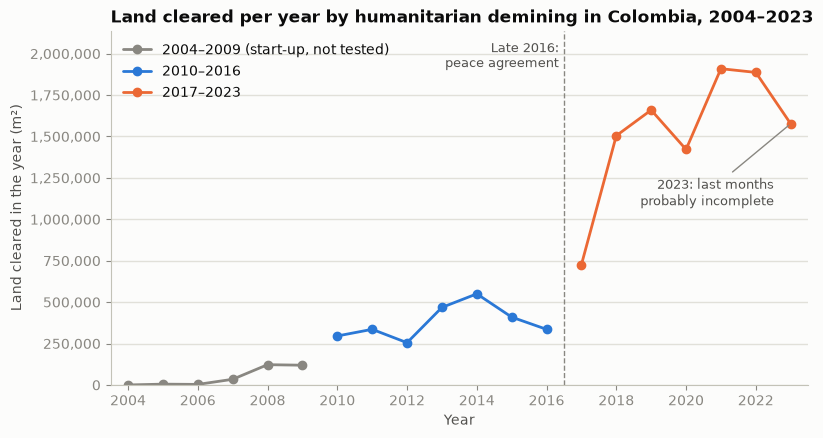

In [19]:
fig, ax = plt.subplots(figsize=(9, 4.6))
for period in [START_UP, BEFORE, AFTER]:
    part = yearly[yearly["period"] == period]
    label = f"{period} (start-up, not tested)" if period == START_UP else period
    ax.plot(part.index, part["area_cleared_m2"], color=PERIOD_COLOURS[period], marker="o",
            markersize=6, label=label, solid_capstyle="round", solid_joinstyle="round")
top = yearly["area_cleared_m2"].max() * 1.12
ax.axvline(2016.5, color=MUTED, linewidth=1, linestyle="--")
ax.text(2016.35, top * 0.97, "Late 2016:\npeace agreement", ha="right", va="top", color=INK_2, fontsize=9)
last = yearly.loc[2023, "area_cleared_m2"]
ax.annotate("2023: last months\nprobably incomplete", xy=(2023, last), xytext=(-12, -38),
            textcoords="offset points", ha="right", va="top", color=INK_2, fontsize=9,
            arrowprops={"arrowstyle": "-", "color": MUTED, "linewidth": 1})
ax.set_title("Land cleared per year by humanitarian demining in Colombia, 2004–2023")
ax.set_xlabel("Year")
ax.set_ylabel("Land cleared in the year (m²)")
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_xticks(range(2004, 2024, 2))
ax.set_xlim(2003.5, 2023.5)
ax.set_ylim(0, top)
ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
save_fig(fig, "01_land_cleared_per_year.png")
plt.show()

In [20]:
yearly["area_cleared_m2"].round(0).astype(int).rename("land cleared (m²)").to_frame().T

year,2004,2005,2006,2007,2008,2009,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023
land cleared (m²),0,4831,3260,34140,122325,119161,295595,335787,255010,468038,549931,409533,335727,726267,1504715,1659566,1421677,1909198,1886763,1576857


**What it shows:** land cleared stayed below 125,000 m² a year until 2009, ranged from 255,010 to 549,931 m² a year in 2010–2016, then rose to 726,267 m² in 2017 and to between 1,421,677 and 1,909,198 m² a year in 2018–2023. Every year after 2016 cleared more land than any year before. The 2023 total (1,576,857 m²) is probably an undercount, because records thin out from September 2023 (section 2.3).

### 4.2 Monthly totals by period (box plot)

2010–2016: median 31,722 m²; middle half 10,979 to 44,727 m²; range 0 to 102,786 m²; months with zero: 8
2017–2023: median 118,107 m²; middle half 61,895 to 184,724 m²; range 0 to 340,263 m²; months with zero: 1


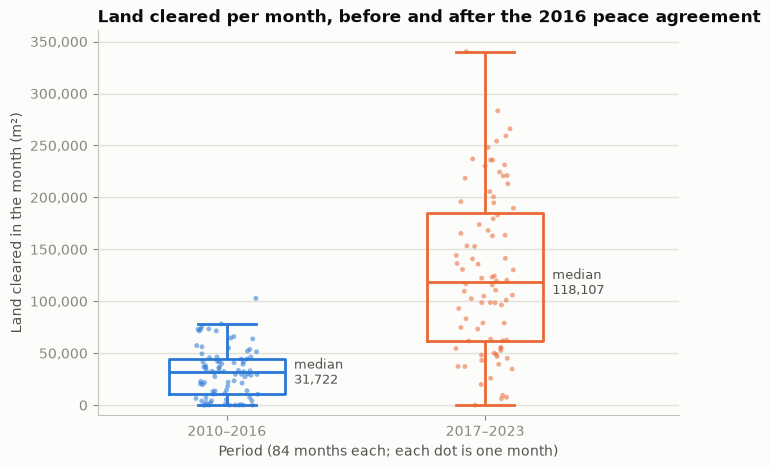

In [21]:
fig, ax = plt.subplots(figsize=(7.5, 5))
sns.boxplot(data=test_months, x="period", y="area_cleared_m2", hue="period", order=ORDER,
            hue_order=ORDER, palette=PERIOD_COLOURS, fill=False, width=0.45, linewidth=2,
            showfliers=False, legend=False, ax=ax)
sns.stripplot(data=test_months, x="period", y="area_cleared_m2", hue="period", order=ORDER,
              hue_order=ORDER, palette=PERIOD_COLOURS, size=3.5, alpha=0.55, jitter=0.12,
              legend=False, ax=ax)
for position, period in enumerate(ORDER):
    median = test_months.loc[test_months["period"] == period, "area_cleared_m2"].median()
    ax.text(position + 0.26, median, f"median\n{median:,.0f}", va="center", ha="left",
            color=INK_2, fontsize=9)
ax.set_title("Land cleared per month, before and after the 2016 peace agreement")
ax.set_xlabel("Period (84 months each; each dot is one month)")
ax.set_ylabel("Land cleared in the month (m²)")
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_ylim(-10_000, test_months["area_cleared_m2"].max() * 1.06)
ax.set_xlim(-0.5, 1.75)
ax.grid(axis="x", visible=False)
for period in ORDER:
    values = test_months.loc[test_months["period"] == period, "area_cleared_m2"]
    print(f"{period}: median {values.median():,.0f} m²; middle half {values.quantile(0.25):,.0f} to "
          f"{values.quantile(0.75):,.0f} m²; range {values.min():,.0f} to {values.max():,.0f} m²; "
          f"months with zero: {values.eq(0).sum()}")
save_fig(fig, "02_monthly_by_period.png")
plt.show()

**What it shows:** the boxes, which hold the middle half of each period's months, do not overlap: about 11,000 to 45,000 m² a month in 2010–2016 against about 62,000 to 185,000 m² in 2017–2023. The median month rose from 31,722 to 118,107 m², about 3.7 times. Months after 2016 also vary far more, from 0 to 340,263 m², and eight of the nine months with zero land cleared fall before 2017.

### 4.3 Distribution of monthly totals by period (histograms)

2010–2016: 73 of 84 months (87%) below 60,000 m²; 1 above 100,000 m²
2017–2023: 20 of 84 months (24%) below 60,000 m²; 50 above 100,000 m²


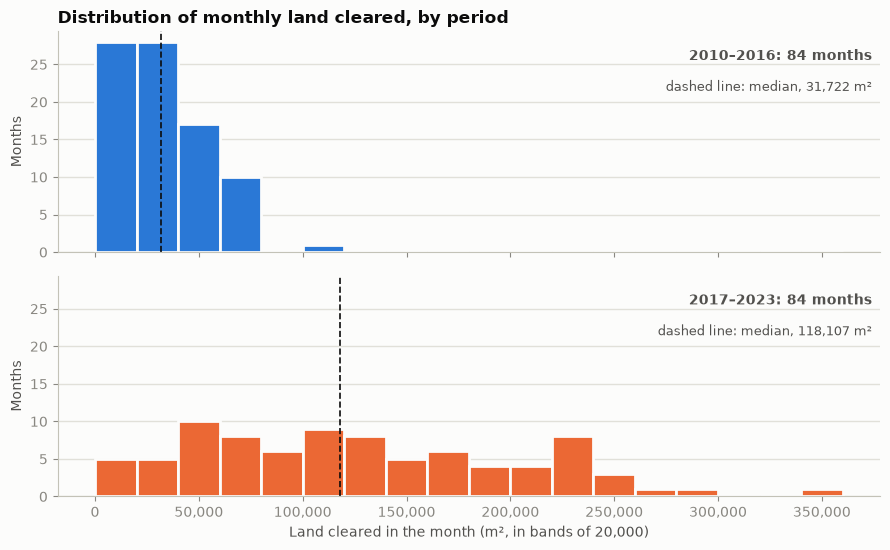

In [22]:
bins = np.arange(0, test_months["area_cleared_m2"].max() + 20_000, 20_000)
fig, axes = plt.subplots(2, 1, figsize=(9, 5.6), sharex=True, sharey=True)
for ax, period in zip(axes, ORDER):
    values = test_months.loc[test_months["period"] == period, "area_cleared_m2"]
    ax.hist(values, bins=bins, color=PERIOD_COLOURS[period], edgecolor=SURFACE, linewidth=2)
    ax.set_ylabel("Months")
    ax.grid(axis="x", visible=False)
    median = values.median()
    ax.axvline(median, color=INK, linewidth=1.2, linestyle="--")
    ax.text(0.99, 0.92, f"{period}: {len(values)} months", transform=ax.transAxes, ha="right",
            va="top", color=INK_2, fontsize=10, fontweight="bold")
    ax.text(0.99, 0.78, f"dashed line: median, {median:,.0f} m²", transform=ax.transAxes,
            ha="right", va="top", color=INK_2, fontsize=9)
axes[0].set_title("Distribution of monthly land cleared, by period")
axes[1].set_xlabel("Land cleared in the month (m², in bands of 20,000)")
axes[1].xaxis.set_major_formatter(THOUSANDS)
fig.tight_layout()
for period in ORDER:
    values = test_months.loc[test_months["period"] == period, "area_cleared_m2"]
    print(f"{period}: {values.lt(60_000).sum()} of {len(values)} months ({values.lt(60_000).mean():.0%}) "
          f"below 60,000 m²; {values.gt(100_000).sum()} above 100,000 m²")
save_fig(fig, "03_monthly_distribution.png")
plt.show()

**What it shows:** in 2010–2016 the months bunch at the low end: 73 of 84 (87%) cleared less than 60,000 m², and only one cleared more than 100,000 m². In 2017–2023 the months spread from 0 to 340,000 m² without a single clear peak, and only 20 of 84 (24%) fell below 60,000 m². The two distributions differ in spread and shape as well as in their centres.

### 4.4 Comparing the visual models

| Visual model | Metric shown | Result, 2010–2016 against 2017–2023 | What it reveals | Trade-off |
|---|---|---|---|---|
| 4.1 Line chart | Total land cleared per year | 255,010–549,931 m² a year against 726,267–1,909,198 m² | When the change happened: a step up in 2017 and 2018 to a new, higher level; it also shows the start-up years and the incomplete 2023 | Hides the month-to-month variation the test works with; seven points per period are too few to judge spread |
| 4.2 Box plot | Median and middle half (25th to 75th percentile) of the 84 monthly totals, with every month as a dot | Median 31,722 against 118,107 m²; middle half 10,979–44,727 against 61,895–184,724 m² | The size of the gap on the test's own unit: the middle halves do not overlap | Loses the order in time, so it cannot show trends within a period or the start-up years |
| 4.3 Histograms | Number of months in each 20,000 m² band | 87% against 24% of months below 60,000 m² | The shape of each distribution: bunching near zero before 2017 and a wide spread after, the reason a rank-based test was chosen | Centres are harder to compare than in the box plot, and the picture depends on the band width |

The **box plot (4.2) best supports the question**, because it shows exactly what the test compares: the national monthly totals of the two periods, with their medians and spreads side by side. The line chart adds the context of when the change happened and the histograms explain the choice of test, but neither compares the two groups of months directly.